## Step 2 — RAD21 on sister cohesin under protein depletion

Integrates the sister-linking cohesin network over time and compares WT with
SORORIN, WAPL, WAPL + SORORIN and PDS5 depletion.

- **Input:** `../Step1_Centroid/parameters_10h.json` and the centroid
  `(x, y) = (0.12028, 0.30274)` from `Step1_Centroid/CRN_centroid.ipynb`.
- **Output:** RAD21 residence time and bound fractions for each depletion
  level, and a plot of the fraction of RAD21 on sister cohesin over time.

Note: this step uses τ_R = 10 h; the Step 3 lattice parameters use 11 h (inferred from experiment).

In [125]:
import json
import numpy as np
import sympy as sym
from sympy import symbols, Eq, pprint
import scipy.integrate
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
sym.init_printing()

### Linker network: PDS5, WAPL, SORORIN, unloading

In [126]:
## Rates
rates_coh = sym.symbols("K_RP_RPW, K_RPW_RP, K_RP_RPS, K_RPS_RP, K_RP_R, K_R_RP, K_RPW_R_free")
K_RP_RPW, K_RPW_RP, K_RP_RPS, K_RPS_RP, K_RP_R, K_R_RP, K_RPW_R_free = rates_coh

## Parameters
parameters_coh = sym.symbols("tau_S, F_S, N_S, tau_W, F_W, N_W, tau_P, F_P, N_P, tau_R, F_R_sister, N_R")
tau_S, F_S, N_S, tau_W, F_W, N_W, tau_P, F_P, N_P, tau_R, F_R_sister, N_R = parameters_coh

rhs_coh = [ K_RPW_R_free * N_W * F_W - F_R_sister*N_R/tau_R,    # RAD21 unbinding
        F_W/(tau_W * (1-F_W)) - K_RP_RPW*(F_P*N_P - F_S*N_S - F_W*N_W), # Wapl binding
        K_RPW_RP + K_RPW_R_free - 1/tau_W,              # Wapl unbinding
        F_S/(tau_S * (1-F_S)) - K_RP_RPS * (F_P*N_P - F_S*N_S - F_W*N_W), # Sororin binding
        K_RPS_RP - 1/tau_S,      # Sororin unbinding
        F_P/(tau_P * (1-F_P)) - K_R_RP * (F_R_sister*N_R - F_P * N_P), # PDS5 binding
        K_RPW_R_free * F_W *N_W + K_RP_R*(F_P*N_P - F_S*N_S - F_W*N_W) - F_P*N_P/tau_P,   # PDS5 unbinding
]

sol_rates_coh = sym.solve(rhs_coh, rates_coh)
## Print equations
for i, eq in enumerate(rhs_coh, 1):
    pprint(Eq(symbols(f"eq_{i}"), eq))

        F_R_sister⋅N_R                       
eq₁ = - ────────────── + F_W⋅K_RPW_R_free⋅N_W
             τ_R                             
           F_W                                              
eq₂ = ───────────── - K_RP_RPW⋅(F_P⋅N_P - F_S⋅N_S - F_W⋅N_W)
      τ_W⋅(1 - F_W)                                         
                                 1 
eq₃ = K_RPW_RP + K_RPW_R_free - ───
                                τ_W
           F_S                                              
eq₄ = ───────────── - K_RP_RPS⋅(F_P⋅N_P - F_S⋅N_S - F_W⋅N_W)
      τ_S⋅(1 - F_S)                                         
                  1 
eq₅ = K_RPS_RP - ───
                 τ_S
           F_P                                          
eq₆ = ───────────── - K_R_RP⋅(-F_P⋅N_P + F_R_sister⋅N_R)
      τ_P⋅(1 - F_P)                                     
        F_P⋅N_P                                                              
eq₇ = - ─────── + F_W⋅K_RPW_R_free⋅N_W + K_RP_R⋅(F_P⋅N_P - F_S⋅N_S - F_W⋅N_W

In [127]:
with open("../Step1_Centroid/parameters_10h.json", "r") as f:
    PARAMS = json.load(f)

In [129]:
def get_parameter_dict_coh(x, y):
    p = PARAMS["cohesive"]
    parameter_values_coh = [
        p["tau_S"],
        p["F_S"],
        p["N_S"],
        p["tau_W"],
        x / (p["x_offset_W"] + x),                        # modified F_W for sister
        p["N_W_base"] * (p["x_offset_W"] + x),            # modified N_W for sister
        p["tau_P"],
        y / (p["y_offset_P"] + y),                        # modified F_P for sister
        p["N_P_base"] * (p["y_offset_P"] + y),            # modified N_P for sister
        p["tau_R_sister"],
        p["F_R_sister"],
        p["N_R_modify"],
    ]
    return dict(zip(parameters_coh, parameter_values_coh))

In [130]:
## x, y = (WAPL, PDS5) centroid fraction bound, from Step1_Centroid/CRN_centroid.ipynb's feasible-region fit
parameter_dict_coh = get_parameter_dict_coh(0.12028, 0.30274)
parameter_dict_coh


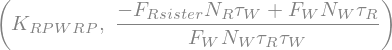

0.0219073226133673


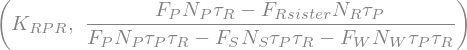

0.156542785420589


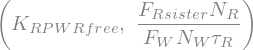

0.000314899608854888


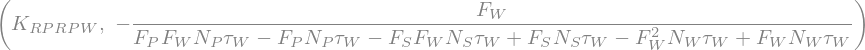

8.50586292019298e-7


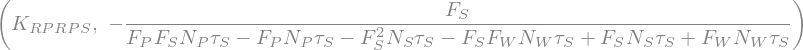

2.24085077555383e-6


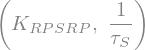

0.0100000000000000


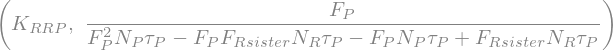

1.80588143214753e-7


In [131]:
for s in sol_rates_coh.items():
    rate = s[1].evalf(subs=parameter_dict_coh)
    parameter_dict_coh[s[0]] = rate
    display(s)
    print(rate)

### Extrusive network: NIPBL, PDS5, WAPL, unloading
##### Rates are solved and shown for reference; this network is not simulated below.

In [132]:
## Rates
rates_ext = sym.symbols("Kext_Rfree_RN, Kext_RN_R, Kext_R_RN, Kext_R_RP, Kext_RP_R, Kext_RP_RPW, Kext_RPW_RP, Kext_RPW_Rfree")
Kext_Rfree_RN, Kext_RN_R, Kext_R_RN, Kext_R_RP, Kext_RP_R, Kext_RP_RPW, Kext_RPW_RP, Kext_RPW_Rfree = rates_ext

## Parameters
parameters_ext = sym.symbols("tau_N_ext, F_N_ext, N_N_ext, tau_W_ext, F_W_ext, N_W_ext, tau_P_ext, F_P_ext, N_P_ext, tau_R_ext, F_R_ext, N_R_ext")
tau_N_ext, F_N_ext, N_N_ext, tau_W_ext, F_W_ext, N_W_ext, tau_P_ext, F_P_ext, N_P_ext, tau_R_ext, F_R_ext, N_R_ext = parameters_ext

rhs_ext = [ Kext_RN_R - 1 / tau_N_ext,  # NIPBL unbinding kinetics
        Kext_Rfree_RN * N_R_ext *(1-F_R_ext) + Kext_R_RN * (N_R_ext*F_R_ext - N_N_ext*F_N_ext - N_P_ext*F_P_ext) -  F_N_ext / tau_N_ext/ (1-F_N_ext), # NIPBL binding equilibrium
        Kext_RP_R * (N_P_ext * F_P_ext - N_W_ext * F_W_ext) + Kext_RPW_Rfree * N_W_ext * F_W_ext  - N_P_ext * F_P_ext/tau_P_ext, # PDS5 unbinding kinetics
        Kext_R_RP * (N_R_ext * F_R_ext - N_N_ext * F_N_ext - N_P_ext * F_P_ext)  - F_P_ext / tau_P_ext /(1-F_P_ext), # PDS5 binding equilibrium,
        Kext_RPW_RP + Kext_RPW_Rfree - 1 / tau_W_ext, # WAPL unbinding kinetics
        Kext_RP_RPW * (N_P_ext * F_P_ext - N_W_ext* F_W_ext)  - F_W_ext / tau_W_ext / (1-F_W_ext), # WAPL binding equilibrium
        Kext_RPW_Rfree * N_W_ext * F_W_ext - F_R_ext * N_R_ext / tau_R_ext,  # RAD21 unbinding kinetics
        Kext_Rfree_RN * N_N_ext * (1-F_N_ext) - F_R_ext / tau_R_ext / (1-F_R_ext) # RAD21 binding equilibrium,
]

sol_rates_ext = sym.solve(rhs_ext, rates_ext)
## Print equations
for i, eq in enumerate(rhs_ext, 1):
    pprint(Eq(symbols(f"eq_{i}"), eq))

                     1   
eq₁ = Kext_RN_R - ───────
                  τ_N_ext
               F_N_ext                                                        
eq₂ = - ───────────────────── + Kext_R_RN⋅(-F_N_ext⋅N_N_ext - F_P_ext⋅N_P_ext 
        τ_N_ext⋅(1 - F_N_ext)                                                 

                                                        
+ F_R_ext⋅N_R_ext) + Kext_Rfree_RN⋅N_R_ext⋅(1 - F_R_ext)
                                                        
        F_P_ext⋅N_P_ext                                                       
eq₃ = - ─────────────── + F_W_ext⋅Kext_RPW_Rfree⋅N_W_ext + Kext_RP_R⋅(F_P_ext⋅
            τ_P_ext                                                           

                          
N_P_ext - F_W_ext⋅N_W_ext)
                          
               F_P_ext                                                        
eq₄ = - ───────────────────── + Kext_R_RP⋅(-F_N_ext⋅N_N_ext - F_P_ext⋅N_P_ext 
        τ_P_ext⋅(1 - F_P_ext)       

In [133]:
def get_parameter_dict_ext(x, y):
    p = PARAMS["extrusive"]
    parameter_values_ext = [
        p["tau_N"],
        p["F_N"],
        p["N_N"],
        p["tau_W"],
        (p["F_W_base"] - x) / (1 - x),                   # modified F_W for extrusive
        p["N_W_base"] * (1 - x),                          # modified N_W for extrusive
        p["tau_P"],
        (p["F_P_base"] - y) / (1 - y),                   # modified F_P for extrusive
        p["N_P_base"] * (1 - y),                          # modified N_P for extrusive
        p["tau_R_extrusive"],
        p["F_R_sister"],
        p["N_R_modify"],
    ]
    return dict(zip(parameters_ext, parameter_values_ext))


In [134]:
## x, y = (WAPL, PDS5) centroid fraction bound, from Step1_Centroid/CRN_centroid.ipynb's feasible-region fit
parameter_dict_ext = get_parameter_dict_ext(0.12028, 0.30274)
parameter_dict_ext

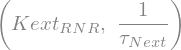

0.0125000000000000


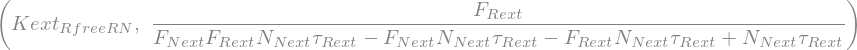

2.32824100460805e-8


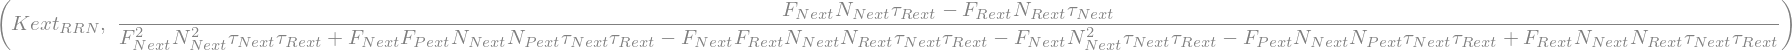

2.36316731037998e-7


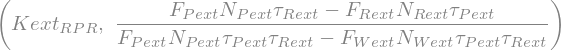

0.0261567749110340


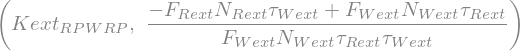

0.0123294505994469


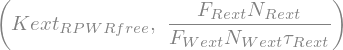

0.00989277162277536


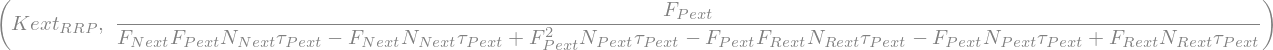

1.08326319566134e-7


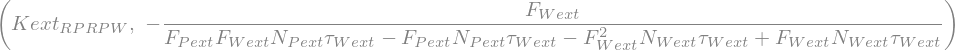

1.50924053602677e-6


In [135]:
for s in sol_rates_ext.items():
    rate = s[1].evalf(subs=parameter_dict_ext)
    parameter_dict_ext[s[0]] = rate
    display(s)
    print(rate)

### Time-course simulation 

In [137]:
COH_SPECIES = ("R", "P", "RP", "S", "RPS", "W", "RPW", "R_free")


def coh_rhs(t, y, k):
    """Mass-action right-hand side of the cohesive network.

        R + P  <-> RP
        RP + S <-> RPS
        RP + W <-> RPW
        RPW     -> R_free + P + W
    """
    R, P, RP, S, RPS, W, RPW, R_free = y
    v1 = k["K_R_RP"] * R * P - k["K_RP_R"] * RP
    v2 = k["K_RP_RPS"] * RP * S - k["K_RPS_RP"] * RPS
    v3 = k["K_RP_RPW"] * RP * W - k["K_RPW_RP"] * RPW
    v4 = k["K_RPW_R_free"] * RPW
    return [-v1, -v1 + v4, v1 - v2 - v3, -v2, v2, -v3 + v4, v3 - v4, v4]


def simulate_coh(params, t_end, n_points):
    """Integrate from the *_init values in params; returns a DataFrame with a time column."""
    k = {str(key): float(value) for key, value in params.items()}
    y0 = [k[f"{s}_init"] for s in COH_SPECIES]
    t = np.linspace(0, t_end, n_points)
    sol = scipy.integrate.solve_ivp(coh_rhs, (0, t_end), y0, method="LSODA",
                                    t_eval=t, args=(k,), rtol=1e-8, atol=1e-10)
    return pd.DataFrame(np.column_stack([t, sol.y.T]), columns=("time",) + COH_SPECIES)


def plot_species(df):
       """Plot every species against time in hours."""
       fig, ax = plt.subplots()
       for s in COH_SPECIES:
           ax.plot(df["time"] / 3600, df[s], label=s)
       ax.set_xlabel("Time [h]")
       ax.legend()

In [138]:
init_conditions = {
      "R_free_init": 0, "R_init": parameter_dict_coh[N_R],
      "RPW_init": 0, "RPS_init": 0, "RP_init": 0,
      "S_init": parameter_dict_coh[N_S], "W_init": parameter_dict_coh[N_W],
      "P_init": parameter_dict_coh[N_P],
  }
parameter_dict = parameter_dict_coh | init_conditions

In [139]:
parameter_dict_string_keys = {str(key): value for key, value in parameter_dict.items()}

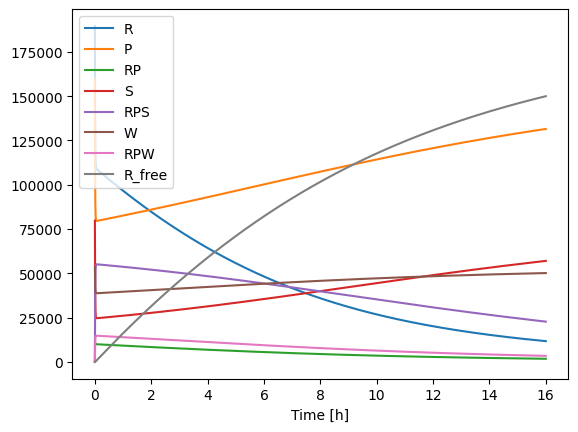

In [140]:
df_WT = simulate_coh(parameter_dict_string_keys, 3600 * 16, 100000)
last = df_WT.iloc[-1]          # state at 16 h

plot_species(df_WT)

### Quantities of interest

In [141]:
def RAD21_bound_time(K_RPW_R_free, B_W, F_R_free, N_R):
    """Effective RAD21 residence time on sister cohesin, in seconds.

    RAD21 is released only from the WAPL-bound state (RPW -> R_free + P + W),
    so the release flux is K_RPW_R_free * B_W. Dividing the bound pool by
    that flux gives the residence time (first equation of rhs_coh):

        tau_R = (N_R - R_free) / (K_RPW_R_free * B_W)

    Args:
        K_RPW_R_free: release rate constant from RPW, in 1/s.
        B_W: number of WAPL-bound cohesins (RPW).
        F_R_free: number (not fraction) of released RAD21 (R_free).
        N_R: total RAD21.
    """
    return (N_R - F_R_free)/(K_RPW_R_free * B_W)

tau_R_WT = RAD21_bound_time(K_RPW_R_free=parameter_dict[K_RPW_R_free], B_W=last["RPW"],
                            F_R_free=last["R_free"], N_R=parameter_dict[N_R])
print(f"tau_R: {tau_R_WT / 3600:.2f} h")

tau_R: 10.25 h


In [142]:
def WAPL_bound_time(K_RPW_RP, K_RPW_R_free):
    """Mean WAPL residence time on cohesin, in seconds.

    WAPL leaves RPW by two routes, RPW -> RP + W and RPW -> R_free + P + W,
    so its residence time is the inverse of the summed exit rates (third
    equation of rhs_coh).
    """
    return 1 / (K_RPW_R_free + K_RPW_RP)


def WAPL_bound_fraction(tau_W, K_RP_RPW, RP):
    """Fraction of WAPL molecules bound to cohesin.

    A WAPL molecule binds available RP with pseudo-first-order rate
    K_RP_RPW * RP and unbinds with rate 1 / tau_W, so the bound fraction is
    k_on / (k_on + k_off) (second equation of rhs_coh). This is a
    per-molecule fraction and does not depend on the total amount of WAPL.
    """
    x = tau_W * K_RP_RPW * RP
    return x / (1 + x)


tau_W = WAPL_bound_time(K_RPW_RP=parameter_dict[K_RPW_RP], K_RPW_R_free=parameter_dict[K_RPW_R_free])
F_W = WAPL_bound_fraction(tau_W=tau_W, K_RP_RPW=parameter_dict[K_RP_RPW], RP=last["RP"])
print(f"tau_W: {tau_W:.1f} s, F_W: {F_W:.3f}")

tau_W: 45.0 s, F_W: 0.064


In [143]:
def SORORIN_bound_time(K_RPS_RP):
    """Mean SORORIN residence time on cohesin, in seconds.

    SORORIN leaves only by RPS -> RP + S, so tau_S = 1 / K_RPS_RP
    (fifth equation of rhs_coh).
    """
    return 1 / K_RPS_RP


def SORORIN_bound_fraction(tau_S, K_RP_RPS, RP):
    """Fraction of SORORIN molecules bound to cohesin.

    Same two-state form as WAPL_bound_fraction, with binding rate
    K_RP_RPS * RP (fourth equation of rhs_coh). Per-molecule, so it is
    not meaningful when SORORIN is fully depleted.
    """
    x = tau_S * K_RP_RPS * RP
    return x / (1 + x)


tau_S = SORORIN_bound_time(K_RPS_RP=parameter_dict[K_RPS_RP])
F_S = SORORIN_bound_fraction(tau_S, K_RP_RPS=parameter_dict[K_RP_RPS], RP=last["RP"])
print(f"tau_S: {tau_S:.1f} s, F_S: {F_S:.3f}")

tau_S: 100.0 s, F_S: 0.285


In [144]:
def PDS5_bound_time(K_RPW_R_free, K_RP_R, RP, W_bound, P_bound):
    """Effective PDS5 residence time on cohesin, in seconds.

    PDS5 is released by RP -> R + P and by RPW -> R_free + P + W; RPS must
    first lose Sororin. The residence time is the bound pool over the total
    release flux (seventh equation of rhs_coh):

        tau_P = P_bound / (K_RPW_R_free * W_bound + K_RP_R * RP)

    Args:
        RP, W_bound: numbers of RP and RPW.
        P_bound: total PDS5-bound cohesin, RP + RPS + RPW.
    """
    return P_bound / (K_RPW_R_free * W_bound + K_RP_R * RP)


def PDS5_bound_fraction(tau_P, K_R_RP, R):
    """Fraction of PDS5 molecules bound to cohesin.

    Two-state form with binding rate K_R_RP * R to PDS5-free cohesin
    (sixth equation of rhs_coh).
    """
    x = tau_P * K_R_RP * R
    return x / (1 + x)


tau_P = PDS5_bound_time(K_RPW_R_free=parameter_dict[K_RPW_R_free], K_RP_R=parameter_dict[K_RP_R],
                        RP=last["RP"], W_bound=last["RPW"],
                        P_bound=last["RP"] + last["RPW"] + last["RPS"])
F_P = PDS5_bound_fraction(tau_P=tau_P, K_R_RP=parameter_dict[K_R_RP], R=last["R"])
print(f"tau_P: {tau_P:.1f} s, F_P: {F_P:.3f}")

tau_P: 100.1 s, F_P: 0.175


In [145]:
def metrics_after(params, hours=6):
    """RAD21 residence time and WAPL/Sororin/PDS5 bound fractions after `hours`."""
    last = simulate_coh(params, 3600 * hours, 2).iloc[-1]
    k = parameter_dict
    tau_W = WAPL_bound_time(K_RPW_RP=k[K_RPW_RP], K_RPW_R_free=k[K_RPW_R_free])
    tau_S = SORORIN_bound_time(K_RPS_RP=k[K_RPS_RP])
    tau_P = PDS5_bound_time(K_RPW_R_free=k[K_RPW_R_free], K_RP_R=k[K_RP_R], RP=last["RP"],
                            W_bound=last["RPW"], P_bound=last["RP"] + last["RPW"] + last["RPS"])
    return {
        "RAD21_h": RAD21_bound_time(K_RPW_R_free=k[K_RPW_R_free], B_W=last["RPW"],
                                    F_R_free=last["R_free"], N_R=k[N_R]) / 3600,
        "F_W": WAPL_bound_fraction(tau_W=tau_W, K_RP_RPW=k[K_RP_RPW], RP=last["RP"]),
        "F_S": SORORIN_bound_fraction(tau_S, K_RP_RPS=k[K_RP_RPS], RP=last["RP"]),
        "F_P": PDS5_bound_fraction(tau_P=tau_P, K_R_RP=k[K_R_RP], R=last["R"]),
    }


def report(label, params):
    m = metrics_after(params)
    print(f"{label:28s} RAD21 {m['RAD21_h']:6.1f} h   "
          f"F_W {m['F_W']:.3f}   F_S {m['F_S']:.3f}   F_P {m['F_P']:.3f}")


base = {str(key): value for key, value in parameter_dict.items()}

### ΔSORORIN

S_init 0% of WT              RAD21    4.9 h   F_W 0.229   F_S 0.635   F_P 0.126
S_init 5% of WT              RAD21    5.1 h   F_W 0.226   F_S 0.631   F_P 0.140
S_init 10% of WT             RAD21    5.4 h   F_W 0.223   F_S 0.627   F_P 0.154
S_init 20% of WT             RAD21    5.8 h   F_W 0.218   F_S 0.619   F_P 0.181
S_init 50% of WT             RAD21    7.3 h   F_W 0.201   F_S 0.596   F_P 0.258


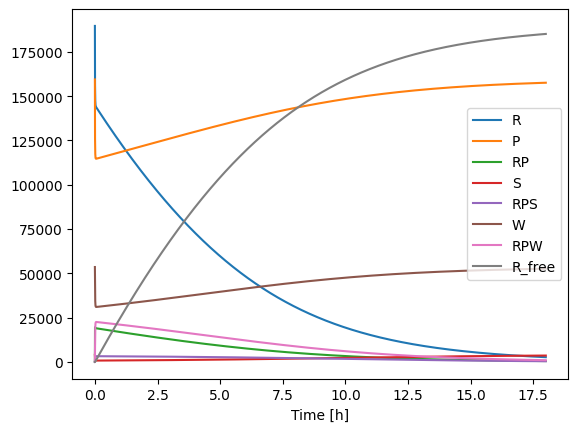

In [146]:
for f in [0, 0.05, 0.1, 0.2, 0.5]:
    report(f"S_init {f:.0%} of WT", dict(base, S_init=f * parameter_dict[N_S]))

## 95% depletion: full trajectory for the summary figure
df_dSORORIN = simulate_coh(dict(base, S_init=0.05 * parameter_dict[N_S]), 3600 * 18, 100000)
plot_species(df_dSORORIN)

### ΔWAPL

W_init 5% of WT              RAD21  195.9 h   F_W 0.309   F_S 0.724   F_P 0.441
W_init 10% of WT             RAD21   97.9 h   F_W 0.300   F_S 0.715   F_P 0.438
W_init 20% of WT             RAD21   48.9 h   F_W 0.283   F_S 0.698   F_P 0.433
W_init 30% of WT             RAD21   32.6 h   F_W 0.267   F_S 0.681   F_P 0.427
W_init 100% of WT            RAD21   10.1 h   F_W 0.175   F_S 0.555   F_P 0.371


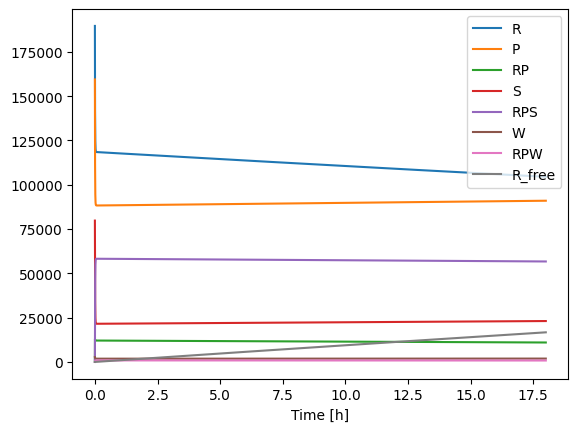

In [147]:
for f in [0.05, 0.1, 0.2, 0.3, 1]:
    report(f"W_init {f:.0%} of WT", dict(base, W_init=f * parameter_dict[N_W]))

## 95% depletion: full trajectory for the summary figure
df_dWapl = simulate_coh(dict(base, W_init=0.05 * parameter_dict[N_W]), 3600 * 18, 100000)
plot_species(df_dWapl)

### ΔWAPL + ΔSORORIN

In [148]:
params_dWdS = dict(base, S_init=0.05 * parameter_dict[N_S], W_init=0.05 * parameter_dict[N_W])
report("S_init 5%, W_init 5% of WT", params_dWdS)

## Full trajectory for the summary figure
df_dWdS = simulate_coh(params_dWdS, 3600 * 18, 100000)

S_init 5%, W_init 5% of WT   RAD21  126.6 h   F_W 0.471   F_S 0.839   F_P 0.175


### ΔPDS5

In [149]:
for f in [0.05, 0.1, 0.2, 0.3, 1]:
    report(f"P_init {f:.0%} of WT", dict(base, P_init=f * parameter_dict[N_P]))

## 95% depletion: full trajectory for the summary figure
df_dPDS5 = simulate_coh(dict(base, P_init=0.05 * parameter_dict[N_P]), 3600 * 18, 100000)

P_init 5% of WT              RAD21  248.4 h   F_W 0.012   F_S 0.068   F_P 0.802
P_init 10% of WT             RAD21  118.4 h   F_W 0.025   F_S 0.131   F_P 0.782
P_init 20% of WT             RAD21   54.4 h   F_W 0.052   F_S 0.242   F_P 0.736
P_init 30% of WT             RAD21   33.9 h   F_W 0.078   F_S 0.331   F_P 0.685
P_init 100% of WT            RAD21   10.1 h   F_W 0.175   F_S 0.555   F_P 0.371


### Summary figure

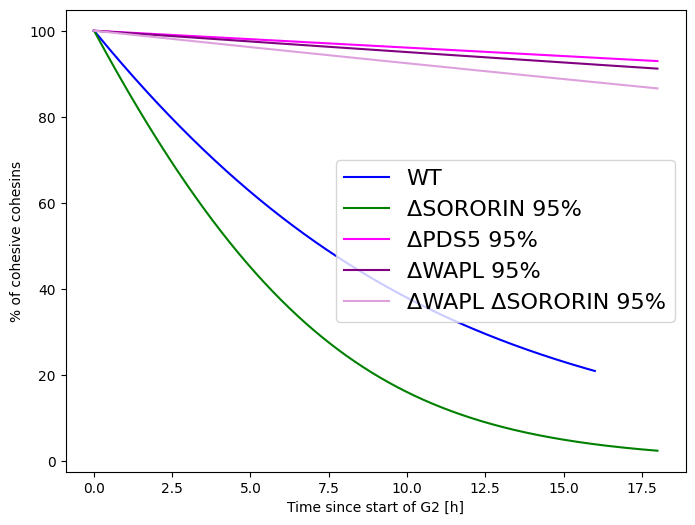

In [151]:
N_R_total = parameter_dict[N_R]
runs = [
    (df_WT,       "WT",                  "blue"),
    (df_dSORORIN, "ΔSORORIN 95%",        "green"),
    (df_dPDS5,    "ΔPDS5 95%",           "magenta"),
    (df_dWapl,    "ΔWAPL 95%",           "purple"),
    (df_dWdS,     "ΔWAPL ΔSORORIN 95%",  "plum"),
]

fig, ax1 = plt.subplots(figsize=(8, 6))
plt.rcParams["svg.fonttype"] = "none"
for df, label, color in runs:
    bound = (N_R_total - df["R_free"]) / N_R_total
    ax1.plot(df["time"] / 3600, 100*bound, label=label, color=color)   # each run on its own time axis
ax1.set_xlabel("Time since start of G2 [h]")
ax1.set_ylabel("% of cohesive cohesins")
ax1.legend(fontsize=16)